In [52]:
# 데이터 가져오기

# 데이터 전처리

# 데이터 분리

# PolynomialFeatures 다항추가

# degree 추가

# 정규화작업

# 데이터 학습

# 규제 적용후 데이터 학습

# alpha값 변경후 데이터 학습 확인

# 데이터 예측

# 정확도




In [55]:
# 그래프관련 import
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
matplotlib.rcParams['axes.unicode_minus']=False

import pandas as pd
import numpy as np
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression 
from sklearn.preprocessing import PolynomialFeatures  # 다항특성 자동생성
from sklearn.linear_model import Ridge
from sklearn.linear_model import Lasso
from sklearn.metrics import mean_absolute_error   # 평균절대값오차 오차범위
from sklearn.preprocessing import StandardScaler  # 정규화클래스
from sklearn.model_selection import train_test_split

In [56]:
df = pd.read_csv('data/MultipleLinearRegressionData.csv')
df.head()

,hour,absent,place,score
0,0.5,3,Home,10
1,1.2,4,Library,8
2,1.8,2,Cafe,14
3,2.4,0,Cafe,26
4,2.6,2,Home,22


In [57]:
data = df.iloc[:,:-2].values
label = df.iloc[:,-1].values
label

array([ 10,   8,  14,  26,  22,  30,  42,  48,  38,  58,  60,  72,  62,
        68,  72,  58,  76,  86,  90, 100])

In [58]:
# 2. 훈련데이터, 테스트데이터 분리
train_data, test_data, train_label, test_label = train_test_split(
 data, label, random_state=42, test_size=0.2
)

In [59]:
# 3. 다항 특성 자동 생성
poly = PolynomialFeatures(degree=5, include_bias=False)
poly.fit(train_data)
train_poly = poly.transform(train_data)
test_poly = poly.transform(test_data)

In [60]:
print(poly.get_feature_names_out())

['x0' 'x1' 'x0^2' 'x0 x1' 'x1^2' 'x0^3' 'x0^2 x1' 'x0 x1^2' 'x1^3' 'x0^4'
 'x0^3 x1' 'x0^2 x1^2' 'x0 x1^3' 'x1^4' 'x0^5' 'x0^4 x1' 'x0^3 x1^2'
 'x0^2 x1^3' 'x0 x1^4' 'x1^5']


In [61]:
# 4. 표준화
ss = StandardScaler()
ss.fit(train_poly)
train_scaled = ss.transform(train_poly)
test_scaled = ss.transform(test_poly)

In [62]:
# 5. 릿지 회귀 - 규제 강도 탐색
train_score = []
test_score = []
alpha_list = [0.001, 0.01, 0.1, 1, 10, 100]
for alpha in alpha_list:
    ridge = Ridge(alpha=alpha)
    ridge.fit(train_scaled, train_label)
    train_score.append(ridge.score(train_scaled, train_label))
    test_score.append(ridge.score(test_scaled, test_label))

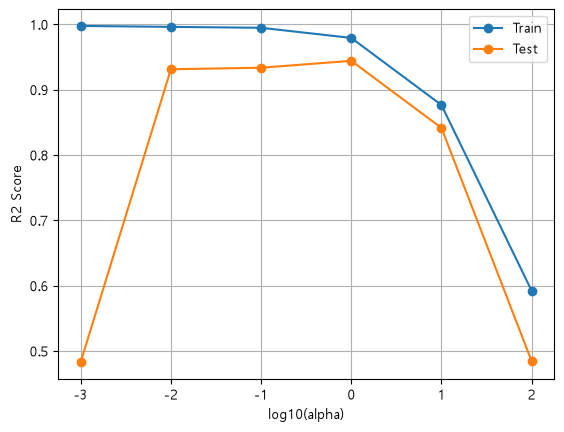

In [63]:
# 6. alpha별 성능 그래프
plt.plot(np.log10(alpha_list), train_score, marker='o')
plt.plot(np.log10(alpha_list), test_score, marker='o')
plt.xlabel('log10(alpha)')
plt.ylabel('R2 Score')
plt.legend(['Train', 'Test'])
plt.grid()
plt.show()

In [64]:
ridge = Ridge(alpha=1)
ridge.fit(train_scaled, train_label)
print('[최종 모델 성능]')
print('훈련 정확도:', ridge.score(train_scaled, train_label))
print('테스트 정확도:', ridge.score(test_scaled, test_label))

[최종 모델 성능]
훈련 정확도: 0.9790927643544124
테스트 정확도: 0.9440422491527587


In [65]:
# 9. 예측 및 오차 확인
result = ridge.predict(test_scaled)
mae = mean_absolute_error(test_label, result)
print('평균 절대 오차(MAE):', mae)

평균 절대 오차(MAE): 7.305847148362432


In [66]:
lr = LinearRegression()
lr.fit(train_poly,train_label)
score = lr.score(train_poly,train_label)
score2 = lr.score(test_poly,test_label)
print(score)
print(score2)

0.9989782314591741
-20.559575800612464
